# 可选实验 - 多类别分类

## 1.1 学习目标
在本实验中，你将探索一个使用神经网络进行多类别分类的例子。
<figure>
 <img src="./images/C2_W2_mclass_header.png"   style="width500px;height:200px;">
</figure>

## 1.2 工具
你将使用一些绘图程序。它们存储在本目录下的 `lab_utils_multiclass_TF.py` 中。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget
from sklearn.datasets import make_blobs
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
np.set_printoptions(precision=2)
from lab_utils_multiclass_TF import *
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

# 2.0 多类别分类
神经网络常用于对数据进行分类。神经网络的例子包括：
- 接收照片，并把照片中的主体分类为 {狗, 猫, 马, 其他}
- 接收一个句子，并对其成分的"词性"进行分类：{名词, 动词, 形容词等..}

这种类型的网络在其最后一层会有多个单元。每个输出都与一个类别相关联。当一个输入样本被应用于网络时，值最高的输出就是预测的类别。如果把输出应用于一个 softmax 函数，softmax 的输出将提供输入属于每个类别的概率。

在本实验中，你将看到一个在 Tensorflow 中构建多类别网络的例子。然后我们将看看神经网络是如何做出预测的。

让我们先创建一个四类别的数据集。

## 2.1 准备并可视化我们的数据
我们将使用 Scikit-Learn 的 `make_blobs` 函数来制作一个含 4 个类别的训练数据集，如下图所示。

In [2]:
# make 4-class dataset for classification
classes = 4
m = 100
centers = [[-5, 2], [-2, -2], [1, 2], [5, -2]]
std = 1.0
X_train, y_train = make_blobs(n_samples=m, centers=centers, cluster_std=std,random_state=30)

d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,


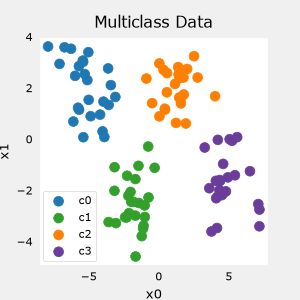

In [3]:
plt_mc(X_train,y_train,classes, centers, std=std)

每个点代表一个训练样本。坐标轴 (x0,x1) 是输入，颜色代表该样本所属的类别。训练完成后，向模型呈现一个新样本 (x0,x1)，它就会预测类别。

尽管是生成的，这个数据集代表了许多现实世界的分类问题。有若干输入特征 (x0,...,xn) 和若干输出类别。模型被训练成使用输入特征来预测正确的输出类别。

In [4]:
# show classes in data set
print(f"unique classes {np.unique(y_train)}")
# show how classes are represented
print(f"class representation {y_train[:10]}")
# show shapes of our dataset
print(f"shape of X_train: {X_train.shape}, shape of y_train: {y_train.shape}")

unique classes [0 1 2 3]
class representation [3 3 3 0 3 3 3 3 2 0]
shape of X_train: (100, 2), shape of y_train: (100,)


## 2.2 模型
<img align="Right" src="./images/C2_W2_mclass_lab_network.PNG"  style=" width:350px; padding: 10px 20px ; ">
本实验将使用一个如图所示的 2 层网络。
与二元分类网络不同，这个网络有四个输出，每个类别一个。给定一个输入样本，值最高的输出就是该输入的预测类别。

下面是在 Tensorflow 中如何构建这个网络的一个例子。请注意，输出层使用 `linear`（线性）激活而不是 `softmax` 激活。虽然可以把 softmax 包含在输出层中，但如果在训练期间把线性输出传给损失函数，数值上会更稳定。如果用该模型来预测概率，可以在那时再应用 softmax。

In [5]:
tf.random.set_seed(1234)  # applied to achieve consistent results
model = Sequential(
    [
        Dense(2, activation = 'relu',   name = "L1"),
        Dense(4, activation = 'linear', name = "L2")
    ]
)

下面的语句编译并训练该网络。把 `from_logits=True` 作为损失函数的一个参数，指定了输出激活是线性的而非 softmax。

In [6]:
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01),
)

model.fit(
    X_train,y_train,
    epochs=200
)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.4464  
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.2004 
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0072 
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8497 
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.7223 
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6206 
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.5369 
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4651 
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4017 
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.3420 
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2862 
Epoch 12/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2339 
Epoch 13/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.1844 
Epoch 14/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.1370 
Epoch 15/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0913 
Epoch 16/200
4/4 ━

模型训练好之后，我们可以看看模型是如何对训练数据进行分类的。

184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 637us/step


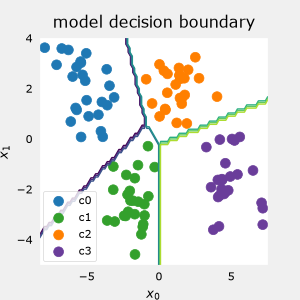

In [7]:
plt_cat_mc(X_train, y_train, model, classes)

在上面，决策边界展示了模型如何划分输入空间。这个非常简单的模型毫不费力地对训练数据进行了分类。它是如何做到的？让我们更详细地看看这个网络。

在下面，我们将从模型中提取训练好的权重，并用它来绘制网络中每个单元的函数。再往下，有对结果更详细的解释。你不需要了解这些细节就能成功使用神经网络，但了解它们可能有助于你对各层如何组合起来解决分类问题获得更多直觉。

In [8]:
# gather the trained parameters from the first layer
l1 = model.get_layer("L1")
W1,b1 = l1.get_weights()

d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,


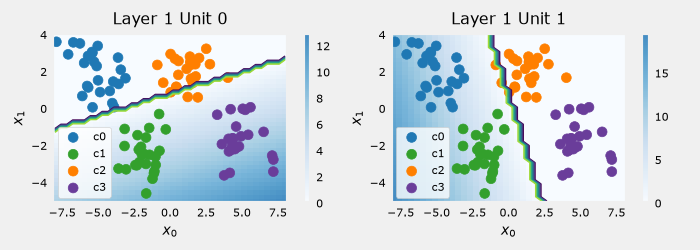

In [9]:
# plot the function of the first layer
plt_layer_relu(X_train, y_train.reshape(-1,), W1, b1, classes)

d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclass_TF.py:63: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(X[idx, 0], X[idx, 1],  marker=m,
d:\workspace_agent\Coursera-Machine-Learning-Specialization-main\Advanced Learning Algorithms\week2\optional labs\lab_utils_multiclas

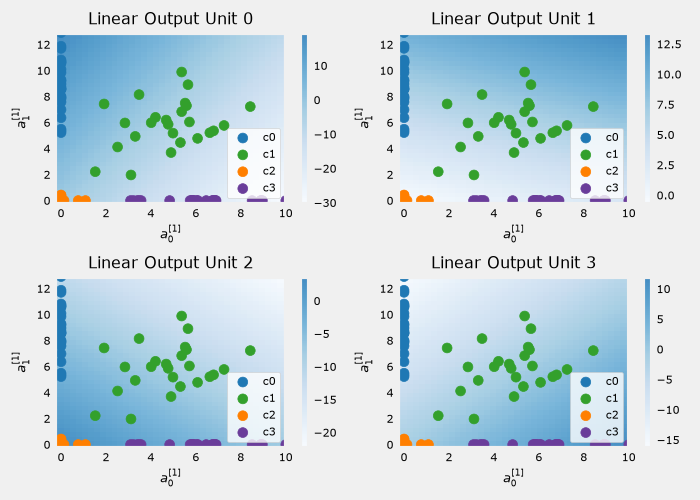

In [10]:
# gather the trained parameters from the output layer
l2 = model.get_layer("L2")
W2, b2 = l2.get_weights()
# create the 'new features', the training examples after L1 transformation
Xl2 = np.maximum(0, np.dot(X_train,W1) + b1)

plt_output_layer_linear(Xl2, y_train.reshape(-1,), W2, b2, classes,
                        x0_rng = (-0.25,np.amax(Xl2[:,0])), x1_rng = (-0.25,np.amax(Xl2[:,1])))

## 解释
#### 第 1 层 <img align="Right" src="./images/C2_W2_mclass_layer1.png"  style=" width:600px; padding: 10px 20px ; ">
这些图展示了网络第一层中 Unit 0 和 Unit 1 的函数。坐标轴上是输入 ($x_0,x_1$)。单元的输出由背景的颜色表示。这由每张图右侧的颜色条指示。请注意，由于这些单元使用 ReLu，输出不一定落在 0 和 1 之间，在本例中其峰值大于 20。
这张图中的等高线显示了输出 $a^{[1]}_j$ 在零与非零之间的转折点。回顾 ReLu 的图像：<img align="right" src="./images/C2_W2_mclass_relu.png"  style=" width:200px; padding: 10px 20px ; "> 图中的等高线就是 ReLu 的拐点。

Unit 0 把类别 0 和 1 与类别 2 和 3 分开了。直线左侧的点（类别 0 和 1）将输出零，而右侧的点将输出一个大于零的值。
Unit 1 把类别 0 和 2 与类别 1 和 3 分开了。直线上方的点（类别 0 和 2）将输出零，而下方的点将输出一个大于零的值。让我们看看这在下一层中是如何运作的！

#### 第 2 层，即输出层  <img align="Right" src="./images/C2_W2_mclass_layer2.png"  style=" width:600px; padding: 10px 20px ; ">

这些图中的点是经过第一层变换后的训练样本。一种理解方式是：第一层创建了一组新的特征，供第 2 层评估。这些图中的坐标轴是前一层的输出 $a^{[1]}_0$ 和 $a^{[1]}_1$。正如上面所预测的，类别 0 和 1（蓝色和绿色）有 $a^{[1]}_0 = 0$，而类别 0 和 2（蓝色和橙色）有 $a^{[1]}_1 = 0$。
同样，背景颜色的强度指示最高的值。
Unit 0 会在接近 (0,0) 的值处产生其最大值，那里正是类别 0（蓝色）被映射到的地方。
Unit 1 在左上角产生其最高值，选择类别 1（绿色）。
Unit 2 针对右下角，那里是类别 2（橙色）所在的位置。
Unit 3 在右上角产生其最高值，选择我们最后的类别（紫色）。

还有一个从图中不易看出的方面：各单元之间的值是被协调过的。一个单元仅仅为它所选择的类别产生最大值是不够的，对于该类别中的点，它还必须是所有单元中最高的值。这是由作为损失函数（`SparseCategoricalCrossEntropy`）一部分的隐含 softmax 函数完成的。与其他激活函数不同，softmax 跨越所有输出进行工作。

你可以在不了解每个单元具体细节的情况下成功使用神经网络。希望这个例子能让你对底层发生的事情有一些直觉。

## 恭喜完成！
你已经学会了构建并运行一个用于多类别分类的神经网络。